# Angela: LDF and AMI area-under-the-curve comparison

Compare **37–137 seconds** with **277–377 seconds**, using `angela_final.csv` and time measured from the common recording start. Each interval lasts exactly **100 seconds**, with 101 samples at 1 Hz when both endpoints are present.

Total recorded signal area is calculated by trapezoidal integration over actual timestamps, including both boundaries. No smoothing, detrending, baseline subtraction, or normalization is applied. AUC units are **source signal units × seconds**. LDF is analyzed as the recorded perfusion signal; AMI is an electrical signal (the source header says BP(uA)), so its integral should not be called blood perfusion without an instrument-specific physiological justification. Verify measurement units before publication. Compare each channel between periods; do not compare absolute LDF AUC with AMI AUC because they have different units and scales.

The reported percentage change uses the first interval as the reference: 100 × (second − first) / first. Two intervals from one participant provide a descriptive comparison, not a statistical test of a population effect.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the data whether launched from pose_analysis or new_pose_detection.
BASE = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'new_pose_detection/data/angela_final.csv').exists()), None)
if BASE is None:
    raise FileNotFoundError('Run this notebook from the pose_analysis folder or a subfolder.')
DATA_PATH = BASE / 'new_pose_detection/data/angela_final.csv'
OUTPUT_DIR = BASE / 'new_pose_detection/auc_comparison_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
PERIODS = [('37–137 s', 37.0, 137.0), ('277–377 s', 277.0, 377.0)]
CHANNELS = {'LDF_bloodflow': 'LDF', 'AMI_bloodflow': 'AMI'}
COLORS = ['tab:blue', 'tab:orange']

raw = pd.read_csv(DATA_PATH).drop(columns=['Unnamed: 0'], errors='ignore')
required = ['time_sec', *CHANNELS]
if not set(required).issubset(raw.columns):
    raise ValueError(f'Missing columns: {set(required) - set(raw.columns)}')
df = raw[required].copy()
if not np.isfinite(df.time_sec).all() or not df.time_sec.is_monotonic_increasing or df.time_sec.duplicated().any():
    raise ValueError('Timestamps must be finite, unique, and increasing.')
print(f'Data: {DATA_PATH.name}; {len(df)} samples; median spacing = {df.time_sec.diff().median():g} s')


Data: angela_final.csv; 585 samples; median spacing = 1 s


## Calculate total area

The notebook requires exact boundary samples and complete one-second coverage in each interval. It raises an error if samples are missing rather than silently bridging gaps. The time-weighted mean equals AUC divided by 100 seconds; it can differ slightly from the arithmetic mean of 101 endpoint-inclusive samples.


In [2]:
def integrate_interval(data, column, start, end):
    window = data.loc[data.time_sec.between(start, end), ['time_sec', column]].copy()
    if len(window) < 2 or window.time_sec.iloc[0] != start or window.time_sec.iloc[-1] != end:
        raise ValueError(f'{column}: interval {start:g}–{end:g} lacks exact boundary samples.')
    if not np.isfinite(window[column]).all():
        raise ValueError(f'{column}: missing or nonfinite values in {start:g}–{end:g}.')
    if not np.allclose(np.diff(window.time_sec), 1.0):
        raise ValueError('Expected complete 1 Hz coverage; verify or explicitly handle gaps before integration.')
    times = window.time_sec.to_numpy(dtype=float)
    values = window[column].to_numpy(dtype=float)
    # Explicit trapezoidal integration: average neighboring values × elapsed time.
    auc = float(np.sum(0.5 * (values[:-1] + values[1:]) * np.diff(times)))
    return window, auc

rows = []
windows = {}
for column, label in CHANNELS.items():
    for period, start, end in PERIODS:
        window, auc = integrate_interval(df, column, start, end)
        windows[(column, period)] = window
        rows.append({'channel': label, 'period': period, 'start_s': start, 'end_s': end,
                     'duration_s': end-start, 'n_samples': len(window),
                     'auc_signal_units_s': auc, 'time_weighted_mean': auc/(end-start)})
auc_table = pd.DataFrame(rows)
comparison_rows = []
for label in CHANNELS.values():
    r = auc_table.loc[auc_table.channel == label].set_index('period')
    first = float(r.loc[PERIODS[0][0], 'auc_signal_units_s'])
    second = float(r.loc[PERIODS[1][0], 'auc_signal_units_s'])
    comparison_rows.append({'channel': label, 'auc_37_137': first, 'auc_277_377': second,
                            'difference_second_minus_first': second-first,
                            'percent_change_from_first': 100*(second-first)/first if first != 0 else np.nan,
                            'second_to_first_ratio': second/first if first != 0 else np.nan})
comparison = pd.DataFrame(comparison_rows)
display(auc_table.round(3))
display(comparison.round(3))
for r in comparison.itertuples():
    print(f'{r.channel}: {r.auc_37_137:,.2f} → {r.auc_277_377:,.2f} signal-unit seconds; '
          f'change {r.difference_second_minus_first:+,.2f} ({r.percent_change_from_first:+.2f}%).')


LDF: 14,212.65 → 17,561.40 signal-unit seconds; change +3,348.75 (+23.56%).
AMI: 288,237.00 → 287,498.00 signal-unit seconds; change -739.00 (-0.26%).


,channel,period,start_s,end_s,duration_s,n_samples,auc_signal_units_s,time_weighted_mean
0,LDF,37–137 s,37.0,137.0,100.0,101,14212.65,142.127
1,LDF,277–377 s,277.0,377.0,100.0,101,17561.40,175.614
2,AMI,37–137 s,37.0,137.0,100.0,101,288237.00,2882.370
3,AMI,277–377 s,277.0,377.0,100.0,101,287498.00,2874.980


,channel,auc_37_137,auc_277_377,difference_second_minus_first,percent_change_from_first,second_to_first_ratio
0,LDF,14212.65,17561.4,3348.75,23.562,1.236
1,AMI,288237.00,287498.0,-739.00,-0.256,0.997


## Visual comparison

The first figure shows each requested interval on the full time axis. The second overlays the intervals on elapsed time within each 100-second window. Shading extends to zero so it represents the total integrated area. The bar charts use separate axes for the two channels.


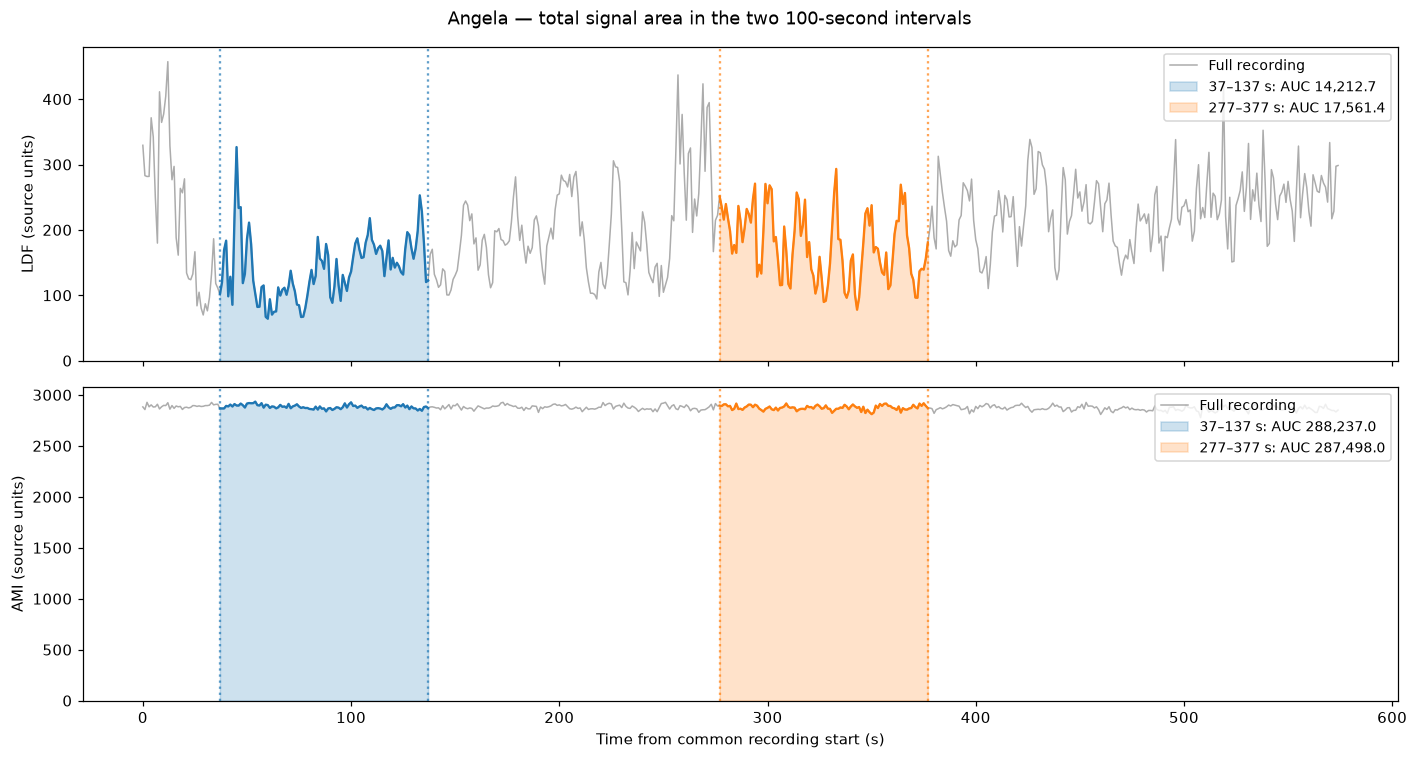

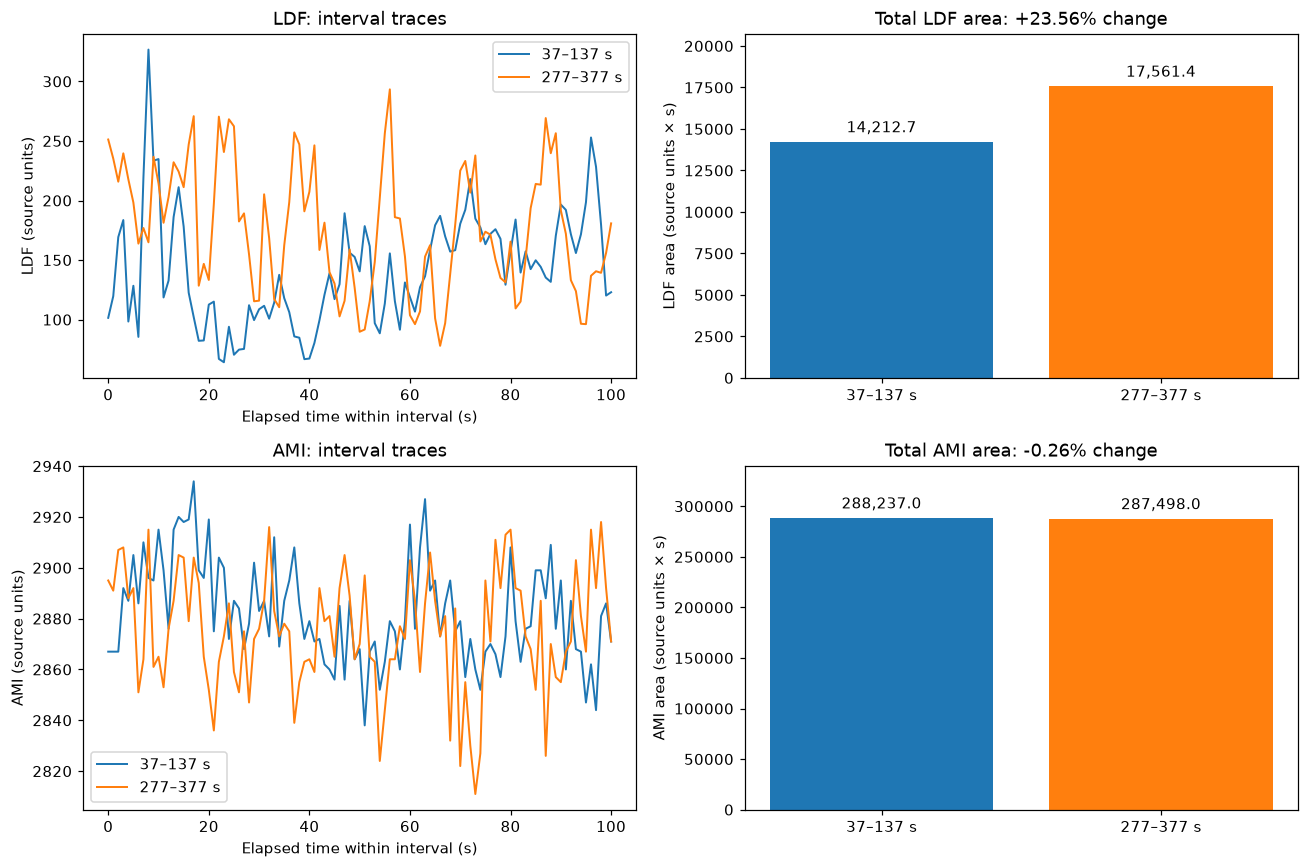

In [3]:
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, (column, label) in zip(axs, CHANNELS.items()):
    ax.plot(df.time_sec, df[column], color='gray', lw=1, alpha=.65, label='Full recording')
    for color, (period, start, end) in zip(COLORS, PERIODS):
        w = windows[(column, period)]
        area = auc_table.loc[(auc_table.channel == label) & (auc_table.period == period), 'auc_signal_units_s'].iloc[0]
        ax.plot(w.time_sec, w[column], color=color, lw=1.5)
        ax.fill_between(w.time_sec, 0, w[column], color=color, alpha=.22,
                        label=f'{period}: AUC {area:,.1f}')
        ax.axvline(start, color=color, ls=':', alpha=.7)
        ax.axvline(end, color=color, ls=':', alpha=.7)
    ax.set_ylabel(f'{label} (source units)')
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper right', fontsize=9)
axs[-1].set_xlabel('Time from common recording start (s)')
fig.suptitle('Angela — total signal area in the two 100-second intervals')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_shaded_intervals.png', dpi=180)
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for i, (column, label) in enumerate(CHANNELS.items()):
    for color, (period, start, end) in zip(COLORS, PERIODS):
        w = windows[(column, period)]
        axs[i, 0].plot(w.time_sec-start, w[column], color=color, label=period, lw=1.3)
    axs[i, 0].set(xlabel='Elapsed time within interval (s)', ylabel=f'{label} (source units)', title=f'{label}: interval traces')
    axs[i, 0].legend()
    r = auc_table.loc[auc_table.channel == label]
    bars = axs[i, 1].bar(r.period, r.auc_signal_units_s, color=COLORS)
    axs[i, 1].bar_label(bars, labels=[f'{v:,.1f}' for v in r.auc_signal_units_s], padding=4)
    pct = comparison.loc[comparison.channel == label, 'percent_change_from_first'].iloc[0]
    axs[i, 1].set(ylabel=f'{label} area (source units × s)', title=f'Total {label} area: {pct:+.2f}% change')
    axs[i, 1].set_ylim(0, r.auc_signal_units_s.max()*1.18)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_traces_and_auc.png', dpi=180)
plt.show()


In [4]:
auc_table.to_csv(OUTPUT_DIR / 'interval_auc.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'auc_comparison.csv', index=False)
for (column, period), window in windows.items():
    start = int(window.time_sec.iloc[0]); end = int(window.time_sec.iloc[-1])
    window.to_csv(OUTPUT_DIR / f'{CHANNELS[column]}_{start}_{end}.csv', index=False)
print(f'Figures and result tables saved to: {OUTPUT_DIR}')


Figures and result tables saved to: C:\Users\Qijun Ma\Documents\GitHub\Analysis-Scripts\pose_analysis\new_pose_detection\auc_comparison_outputs


## Interpretation

A higher total AUC means a larger integrated **recorded signal** over the same duration. Raw AUC includes the baseline, so it does not isolate a movement-induced change. The comparison is descriptive: one person's two time periods may differ in movement, baseline drift, sensor contact, and other conditions. Establish which activities occurred in each period before attaching a physiological interpretation. No significance test is performed because two integrated values per channel do not provide independent replication.
